## 1. Setup and Loading of data 

In [1]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from core.data import load_from_kaggle

# Styling für bessere Visualisierungen
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100



c:\Nitika\Stackfuel_Data_Analyst_Project\Car_sales\Car_sales\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ===== DATASET-LINK =====
full_link = r"https://www.kaggle.com/datasets/gagandeep16/car-sales"
dataset_link = full_link.split("/datasets/")[-1]
# ======================================

destination = "../data/raw"
dataset_name = dataset_link.split("/")[-1]

print(f"📦 Loading Dataset: {dataset_name}")
files = load_from_kaggle(
    dataset_link=dataset_link, 
    destination=destination,
)

print(f"✅ {len(files)} files found:")
for i, file in enumerate(files, 1):
    print(f"   {i}. {file}")


📦 Loading Dataset: car-sales
Destination directory '../data/raw\car-sales' already exists with files. Skipping download (replace=False).
✅ 1 files found:
   1. Car_sales.csv




## 2. Redaing Data & Initial Inspection



In [3]:

# Load the first CSV file
file_path = "/".join([destination, dataset_name, files[0]])
df = pd.read_csv(file_path)

print(f"📊 Loaded File: {files[0]}")
print(f"📏 Shape: {df.shape[0]:,} Rows × {df.shape[1]} Columns\n")

df.sample(10)

📊 Loaded File: Car_sales.csv
📏 Shape: 157 Rows × 16 Columns



,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
141,Toyota,Sienna,65.119,NaN,Car,22.368,3.0,194.0,114.2,73.4,193.5,3.759,20.9,22.0,10/5/2012,78.027219
149,Volkswagen,GTI,5.596,13.760,Passenger,17.500,2.0,115.0,98.9,68.3,163.3,2.762,14.6,26.0,4/1/2011,47.946841
26,Chevrolet,Metro,21.855,5.160,Passenger,9.235,1.0,55.0,93.1,62.6,149.4,1.895,10.3,45.0,4/13/2012,23.276272
71,Lexus,GS300,12.698,32.075,Passenger,37.805,3.0,225.0,110.2,70.9,189.2,3.638,19.8,23.0,5/10/2012,94.946698
92,Mercedes-B,C-Class,18.392,26.050,Passenger,31.750,2.3,185.0,105.9,67.7,177.4,3.250,16.4,26.0,4/24/2011,78.280731
145,Volkswagen,Golf,9.761,11.425,Passenger,14.900,2.0,115.0,98.9,68.3,163.3,2.767,14.5,26.0,1/24/2011,46.943877
123,Pontiac,Montana,39.572,NaN,Car,25.635,3.4,185.0,120.0,72.7,201.3,3.942,25.0,23.0,7/22/2012,76.208440
95,Mercedes-B,SL-Class,3.311,58.600,Passenger,82.600,5.0,302.0,99.0,71.3,177.1,4.125,21.1,20.0,3/17/2011,139.982294
58,Honda,Accord,230.902,13.210,Passenger,15.350,2.3,135.0,106.9,70.3,188.8,2.932,17.1,27.0,5/20/2012,54.269548
63,Hyundai,Elantra,66.692,7.825,Passenger,11.799,2.0,140.0,100.4,66.9,174.0,2.626,14.5,27.0,11/15/2011,54.590045




---

## 3. Data Quality & Structure



In [4]:

print("=" * 80)
print("📋 DATA OVERVIEW")
print("=" * 80)

# Basic Statistics
print(f"\n🔢 Dimensions: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print(f"🔄 Duplicate percentage: {df.duplicated().sum():,} ({df.duplicated().sum()/len(df)*100:.2f}%)")
print(f"💾 Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


📋 DATA OVERVIEW

🔢 Dimensions: 157 Rows × 16 Columns
🔄 Duplicate percentage: 0 (0.00%)
💾 Memory Usage: 0.05 MB


In [ ]:
# Detailed Column Overview
column_info = pd.DataFrame({
    "Data types": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique(),
    "Sample Values": [df[col].dropna().sample(min(3, df[col].notna().sum())).tolist() 
                      if df[col].notna().sum() > 0 else [] 
                      for col in df.columns]
})

column_info = column_info.sort_values("Missing Percentage", ascending=False)
column_info


,Data types,Missing Values,Missing Percentage,Unique Values,Sample Values
__year_resale_value,float64,36,22.93,117,"[19.425, 18.81, 19.925]"
Fuel_efficiency,float64,3,1.91,20,"[15.0, 26.0, 33.0]"
Curb_weight,float64,2,1.27,147,"[5.393, 3.102, 3.051]"
Price_in_thousands,float64,2,1.27,152,"[85.5, 9.699, 33.12]"
Power_perf_factor,float64,2,1.27,154,"[67.35101072, 48.67289791, 102.1789848]"
Wheelbase,float64,1,0.64,88,"[111.0, 115.3, 115.7]"
Engine_size,float64,1,0.64,31,"[3.1, 1.8, 1.9]"
Horsepower,float64,1,0.64,66,"[215.0, 142.0, 253.0]"
Length,float64,1,0.64,127,"[174.5, 174.0, 197.9]"
Width,float64,1,0.64,78,"[71.0, 72.7, 68.4]"




---

## 4. Analyze Numerical Variables



In [6]:

# Analyze Numerical Variables
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if numeric_cols:
    print(f"📊 {len(numeric_cols)} numeric columns found\n")
    display(df[numeric_cols].describe().round(2).T)
else:
    print("⚠️ No numeric columns found")



📊 12 numeric columns found



,count,mean,std,min,25%,50%,75%,max
Sales_in_thousands,157.0,53.00,68.03,0.11,14.11,29.45,67.96,540.56
__year_resale_value,121.0,18.07,11.45,5.16,11.26,14.18,19.88,67.55
Price_in_thousands,155.0,27.39,14.35,9.24,18.02,22.80,31.95,85.50
Engine_size,156.0,3.06,1.04,1.00,2.30,3.00,3.58,8.00
Horsepower,156.0,185.95,56.70,55.00,149.50,177.50,215.00,450.00
Wheelbase,156.0,107.49,7.64,92.60,103.00,107.00,112.20,138.70
Width,156.0,71.15,3.45,62.60,68.40,70.55,73.43,79.90
Length,156.0,187.34,13.43,149.40,177.58,187.90,196.12,224.50
Curb_weight,155.0,3.38,0.63,1.90,2.97,3.34,3.80,5.57
Fuel_capacity,156.0,17.95,3.89,10.30,15.80,17.20,19.58,32.00


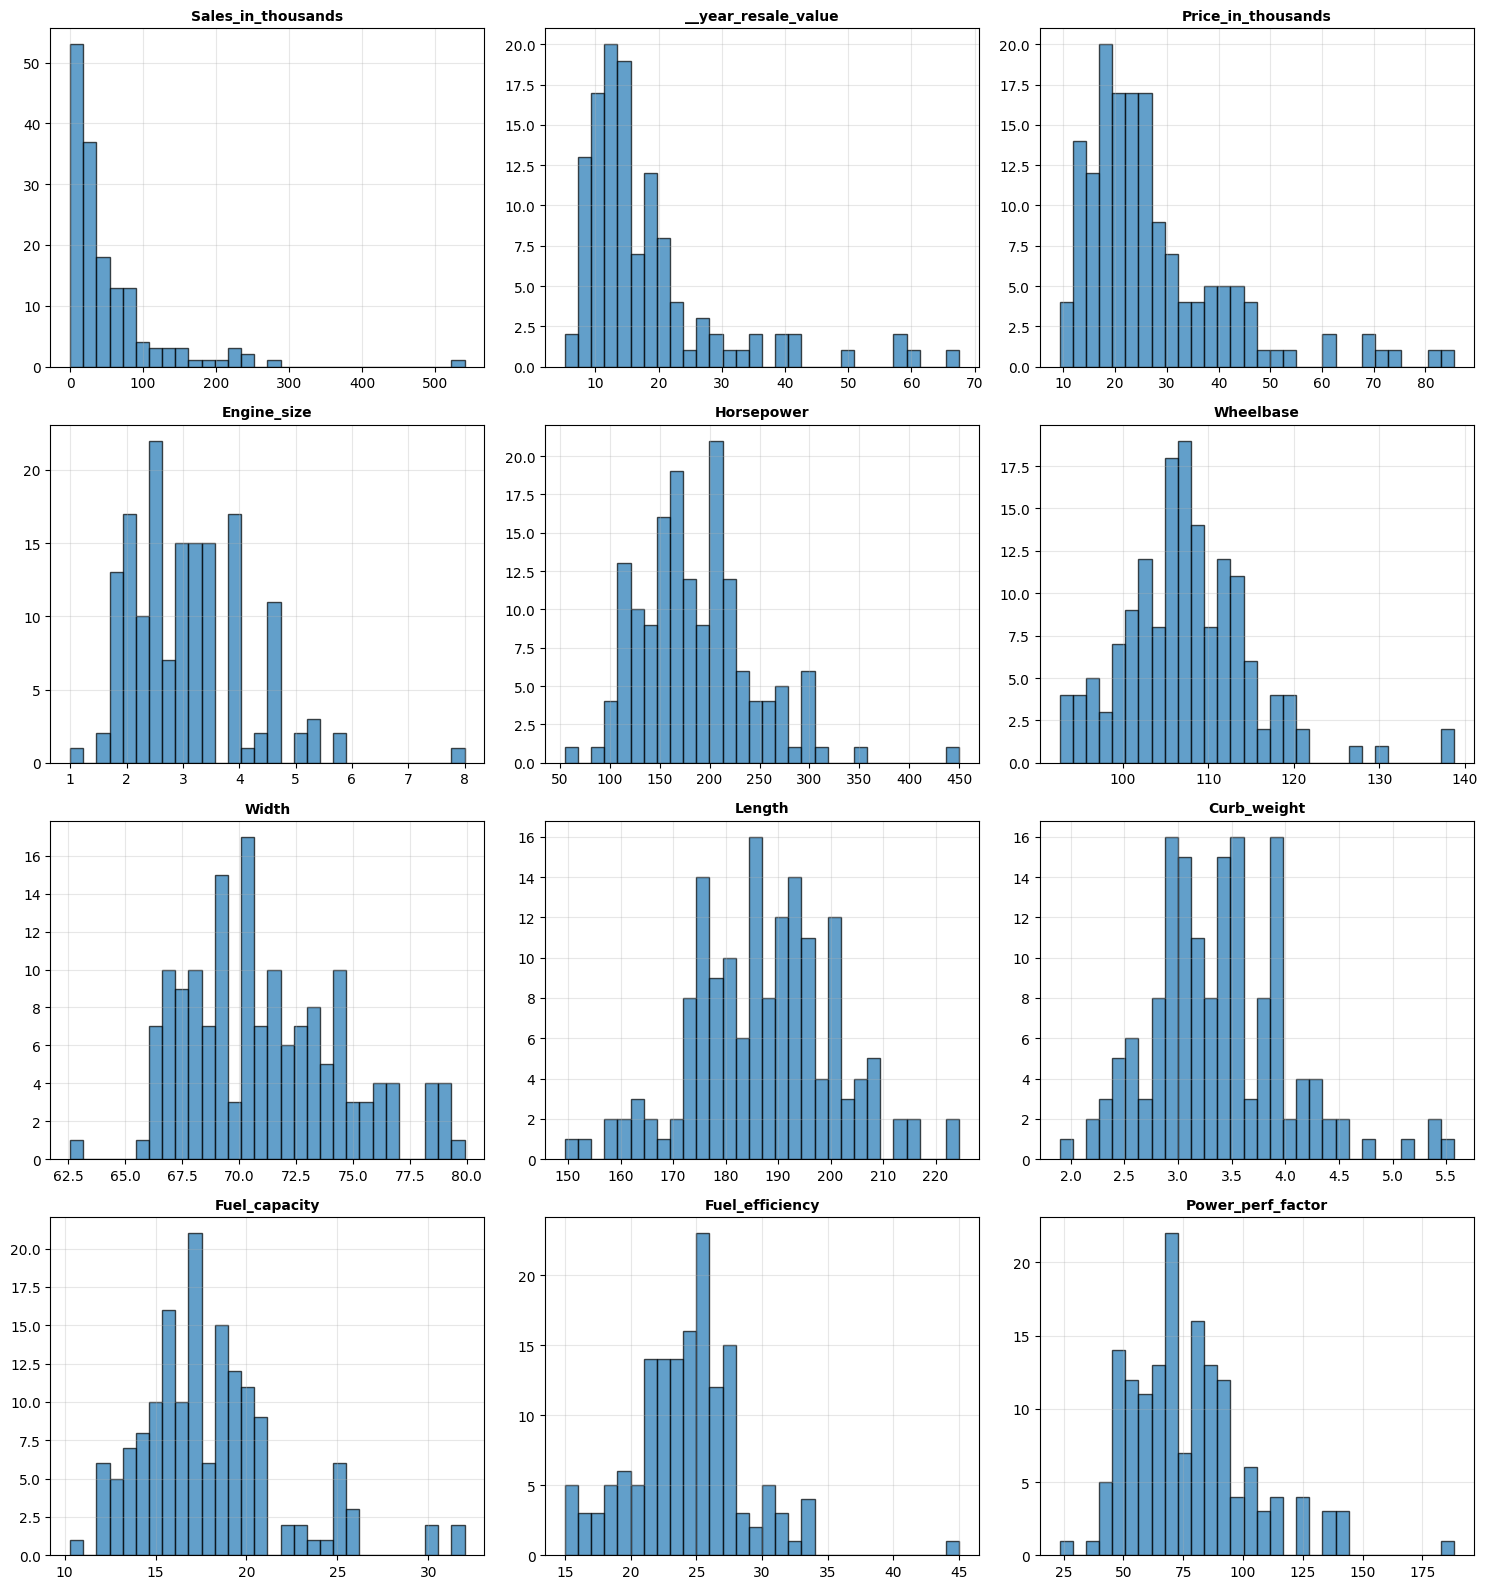

In [ ]:
# Distributions of Numerical Variables
if numeric_cols:
    n_cols = min(3, len(numeric_cols))
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
    axes = axes.flatten() if len(numeric_cols) > 1 else [axes]
    
    for idx, col in enumerate(numeric_cols):
        ax = axes[idx]
        df[col].hist(bins=30, ax=ax, edgecolor='black', alpha=0.7)
        ax.set_title(f'{col}', fontsize=10, fontweight='bold')
        ax.grid(alpha=0.3)
    
    # Hide empty subplots
    for idx in range(len(numeric_cols), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()




---

## 5. Kategorische Variablen analysieren



In [8]:

# Kategorische Spalten identifizieren
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if categorical_cols:
    print(f"🏷️ {len(categorical_cols)} kategorische Spalten gefunden\n")
    
    cat_summary = pd.DataFrame({
        "Spalte": categorical_cols,
        "Unique Werte": [df[col].nunique() for col in categorical_cols],
        "Häufigste Werte": [df[col].value_counts().head(3).to_dict() for col in categorical_cols]
    })
    
    display(cat_summary)
else:
    print("⚠️ Keine kategorischen Spalten gefunden")


🏷️ 5 kategorische Spalten gefunden



,Spalte,Unique Werte,Häufigste Werte
0,Name,891,"{'Braund, Mr. Owen Harris': 1, 'Cumings, Mrs. ..."
1,Sex,2,"{'male': 577, 'female': 314}"
2,Ticket,681,"{'347082': 7, '1601': 7, 'CA. 2343': 7}"
3,Cabin,147,"{'G6': 4, 'C23 C25 C27': 4, 'B96 B98': 4}"
4,Embarked,3,"{'S': 644, 'C': 168, 'Q': 77}"


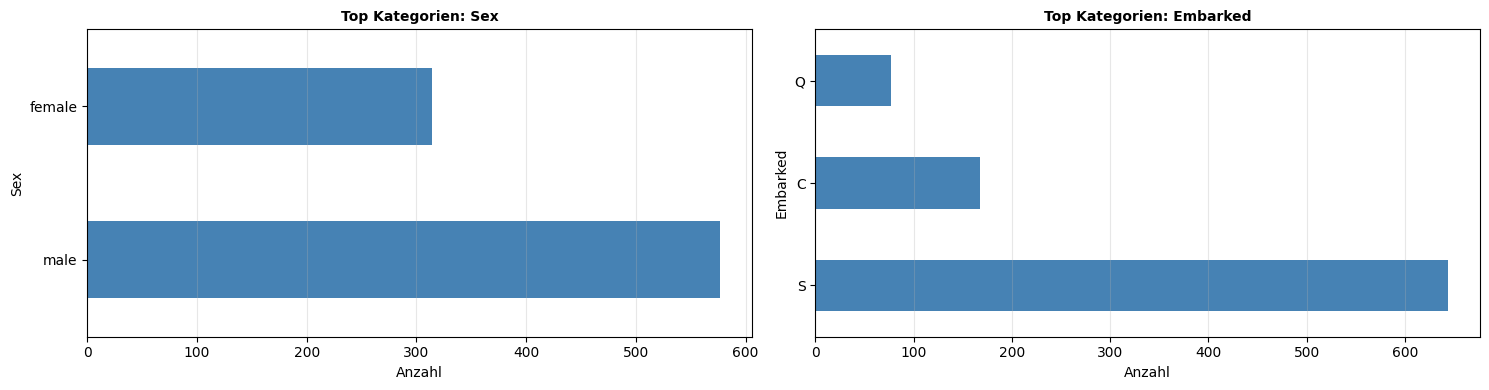

In [9]:
# Top-Kategorien visualisieren (für Spalten mit wenigen Unique-Werten)
if categorical_cols:
    low_cardinality_cols = [col for col in categorical_cols if df[col].nunique() <= 20]
    
    if low_cardinality_cols:
        n_cols = min(2, len(low_cardinality_cols))
        n_rows = (len(low_cardinality_cols) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
        axes = axes.flatten() if len(low_cardinality_cols) > 1 else [axes]
        
        for idx, col in enumerate(low_cardinality_cols):
            ax = axes[idx]
            value_counts = df[col].value_counts().head(10)
            value_counts.plot(kind='barh', ax=ax, color='steelblue')
            ax.set_title(f'Top Kategorien: {col}', fontsize=10, fontweight='bold')
            ax.set_xlabel('Anzahl')
            ax.grid(alpha=0.3, axis='x')
        
        # Leere Subplots ausblenden
        for idx in range(len(low_cardinality_cols), len(axes)):
            axes[idx].axis('off')
        
        plt.tight_layout()
        plt.show()




---

## 6. Korrelationsanalyse



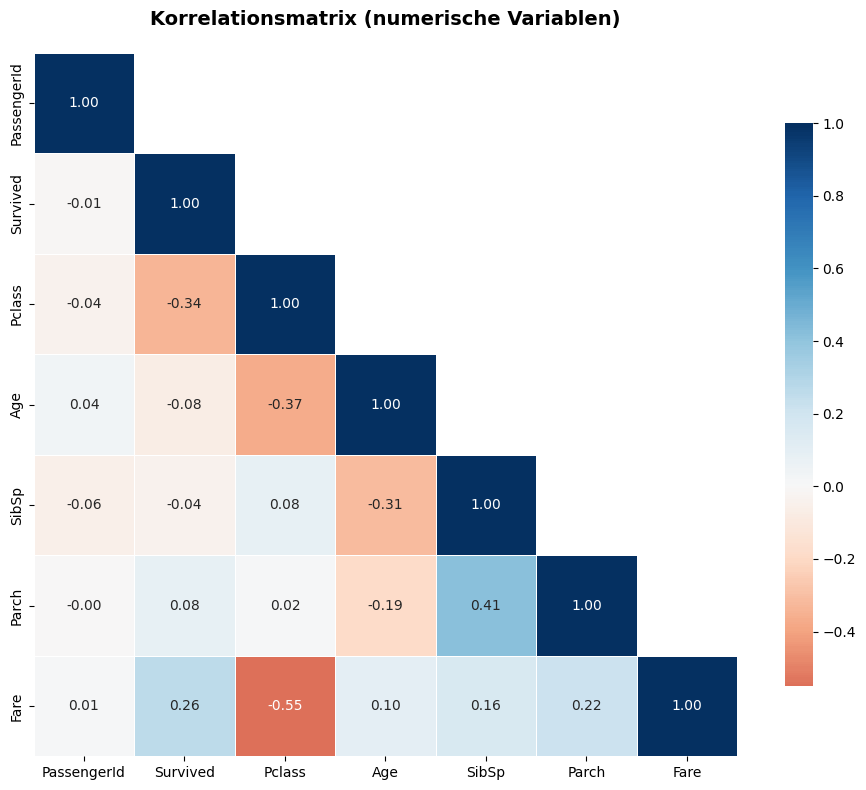


🔗 Stärkste Korrelationen (|r| > 0.5):



,Variable 1,Variable 2,Korrelation
0,Pclass,Fare,-0.5495


In [10]:

if len(numeric_cols) > 1:
    # Korrelationsmatrix
    corr_matrix = df[numeric_cols].corr()
    
    # Heatmap
    fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # Obere Dreiecksmatrix maskieren
    
    sns.heatmap(
        corr_matrix, 
        mask=mask,
        annot=True, 
        fmt='.2f',
        cmap='RdBu', 
        center=0, 
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        ax=ax
    )
    
    ax.set_title('Korrelationsmatrix (numerische Variablen)', 
                 fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()
    
    # Stärkste Korrelationen finden
    print("\n🔗 Stärkste Korrelationen (|r| > 0.5):\n")
    corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > 0.5:
                corr_pairs.append({
                    'Variable 1': corr_matrix.columns[i],
                    'Variable 2': corr_matrix.columns[j],
                    'Korrelation': corr_matrix.iloc[i, j]
                })
    
    if corr_pairs:
        corr_df = pd.DataFrame(corr_pairs).sort_values('Korrelation', 
                                                        key=abs, 
                                                        ascending=False)
        display(corr_df)
    else:
        print("Keine starken Korrelationen gefunden.")
else:
    print("⚠️ Nicht genügend numerische Variablen für Korrelationsanalyse")




---

## 7. Fehlende Werte visualisieren



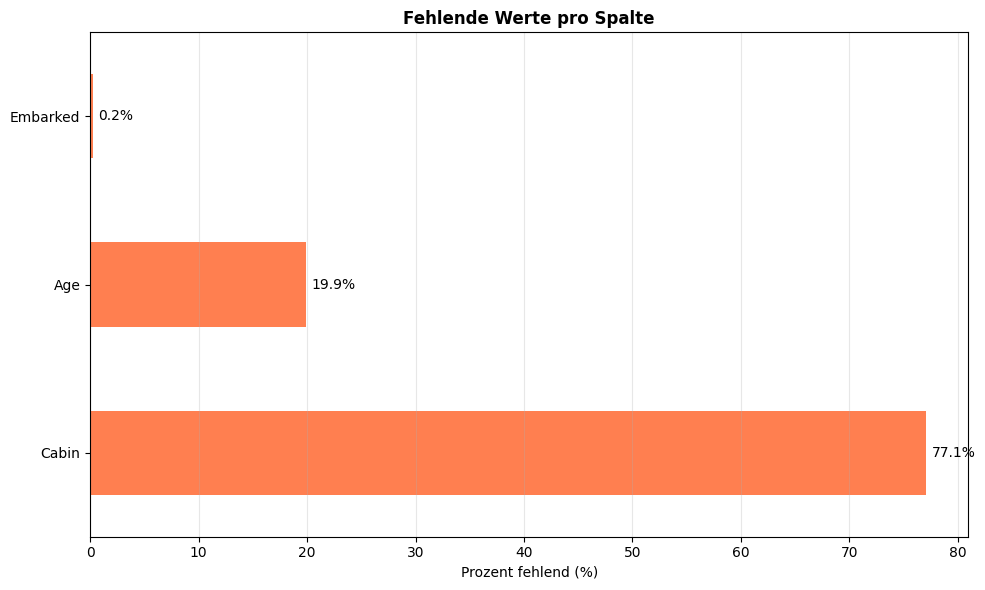

In [11]:

missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

if len(missing_data) > 0:
    fig, ax = plt.subplots(figsize=(10, max(6, len(missing_data) * 0.4)))
    
    missing_percent = (missing_data / len(df) * 100)
    missing_percent.plot(kind='barh', ax=ax, color='coral')
    
    ax.set_title('Fehlende Werte pro Spalte', fontsize=12, fontweight='bold')
    ax.set_xlabel('Prozent fehlend (%)')
    ax.grid(alpha=0.3, axis='x')
    
    # Werte als Text hinzufügen
    for i, v in enumerate(missing_percent):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
    
    plt.tight_layout()
    plt.show()
else:
    print("✅ Keine fehlenden Werte im Dataset!")




---

## 8. Zusammenfassung & Bewertung



In [12]:

print("=" * 80)
print("📝 DATASET-BEWERTUNG FÜR PORTFOLIO-PROJEKT")
print("=" * 80)

# Qualitätskriterien berechnen
data_quality = {
    "Datengröße": "✅ Gut" if len(df) > 5_000 else "⚠️ Klein" if len(df) > 1_000 else "❌ Zu klein",
    "Vollständigkeit": f"✅ {(1 - df.isnull().sum().sum() / (df.shape[0] * df.shape[1])) * 100:.1f}%",
    "Duplikate": "✅ Keine" if df.duplicated().sum() == 0 else f"⚠️ {df.duplicated().sum()} gefunden",
    "Variablenvielfalt": f"{'✅' if df.shape[1] >= 10 else '⚠️'} {df.shape[1]} Spalten",
    "Numerische Features": f"{'✅' if len(numeric_cols) >= 5 else '⚠️'} {len(numeric_cols)} Spalten",
    "Kategorische Features": f"{'✅' if len(categorical_cols) >= 1 else '⚠️'} {len(categorical_cols)} Spalten"
}

for criterion, status in data_quality.items():
    print(f"{criterion:.<30} {status}")

print("\n" + "=" * 80)
print("💡 EMPFEHLUNG:")
print("=" * 80)

score = sum([
    len(df) > 5000,
    df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) < 0.1,
    df.duplicated().sum() < len(df) * 0.05,
    df.shape[1] >= 10,
    len(numeric_cols) >= 5
])

if score >= 4:
    print("✅ SEHR GUT - Dieses Dataset eignet sich hervorragend für ein Portfolio-Projekt!")
elif score >= 3:
    print("👍 OK - Dieses Dataset ist für ein Portfolio-Projekt geeignet.")
else:
    print("⚠️ BEDINGT - Überlege, ob dieses Dataset für dein Projekt ausreicht.")

print("\n📌 Nächste Schritte:")
print("   1. Definiere deine Forschungsfrage")
print("   2. Identifiziere relevante Features")
print("   3. Plane deine Analysestrategie")
print("   4. Beginne mit Feature Engineering & Modeling")


📝 DATASET-BEWERTUNG FÜR PORTFOLIO-PROJEKT
Datengröße.................... ❌ Zu klein
Vollständigkeit............... ✅ 91.9%
Duplikate..................... ✅ Keine
Variablenvielfalt............. ✅ 12 Spalten
Numerische Features........... ✅ 7 Spalten
Kategorische Features......... ✅ 5 Spalten

💡 EMPFEHLUNG:
✅ SEHR GUT - Dieses Dataset eignet sich hervorragend für ein Portfolio-Projekt!

📌 Nächste Schritte:
   1. Definiere deine Forschungsfrage
   2. Identifiziere relevante Features
   3. Plane deine Analysestrategie
   4. Beginne mit Feature Engineering & Modeling
